**step1: Importing required libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


**step2: Load Dataset**

In [2]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\train.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**step3: Exploring the Dataset**

In [3]:
df.shape

(614, 13)

In [4]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [6]:
df.dtypes

Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

**check duplicates values**

In [7]:
df.duplicated().sum()

np.int64(0)

**Droping duplicate rows**

In [8]:
df.drop_duplicates(inplace=True)

**Missing value check**

In [9]:
df.isna().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

**Seperate out numerical columns & categorical columns**

In [10]:
numerical_cols = df.select_dtypes(include='number').columns
numerical_cols

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='str')

In [11]:
numerical_cols = df.select_dtypes(include='number').columns
categorical_cols = df.select_dtypes(include = 'object').columns
categorical_cols

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area', 'Loan_Status'],
      dtype='str')

**checking outliers for imputation of missing values**

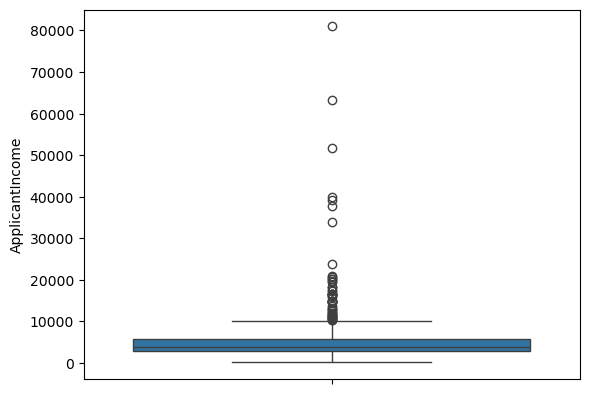

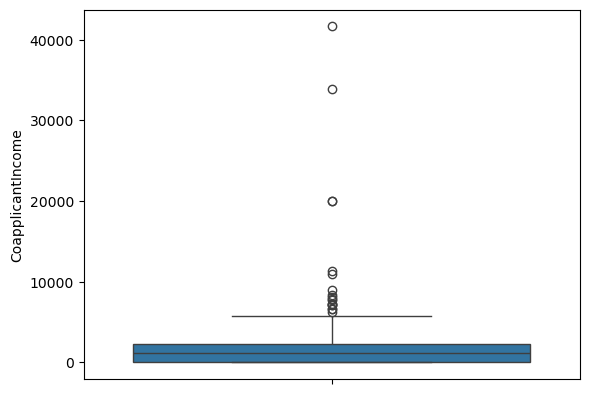

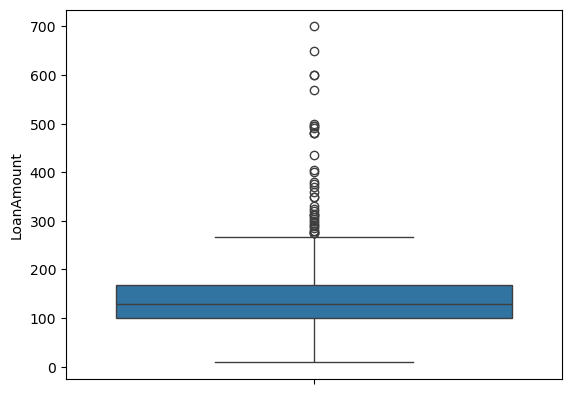

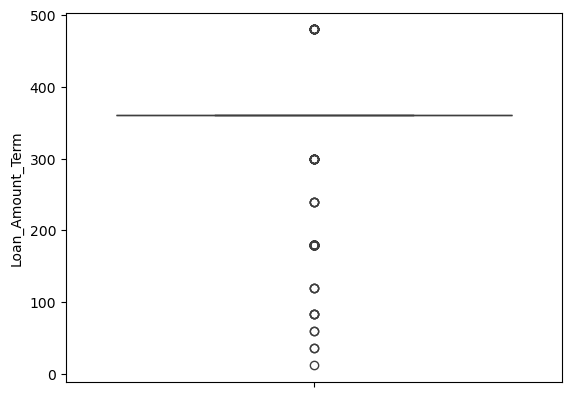

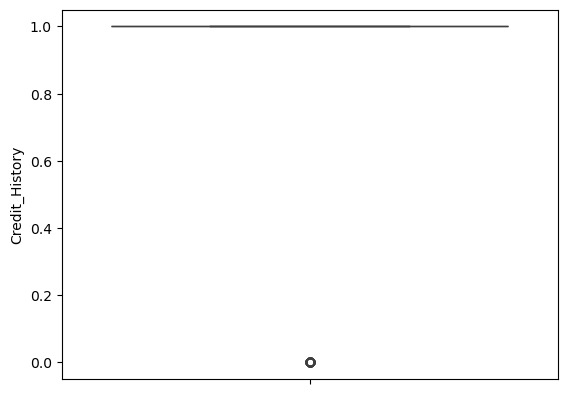

In [12]:
import matplotlib.pyplot  as plt
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

**Handling outliers**

In [13]:
#What is an outlier?
#An outlier is an observation that is for away from most of the other observation(extreme values)
#Example: age: 22,25,27,299,31,28,150
#Here 150 is an outlier

In [14]:
#First detect outliers using IQR method
#Formula IQR(Inter Quartile Range) = Q3-Q1
#Lower bound = Q1-1.5*IQR
#Upper bound = Q3+1.5*IQR
#The data points that fall below lower bound & upper bound are considered as outllier.

In [15]:
numerical_cols 

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='str')

In [16]:
for i in numerical_cols:
        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.25)

        IQR = Q3=Q1

        lower = Q1-1.5*IQR
        upper = Q3+1.5*IQR

        outliers = ((df[i]<lower)|(df[i]>upper)).sum()

        print(i,"=",outliers)

ApplicantIncome = 99
CoapplicantIncome = 341
LoanAmount = 52
Loan_Amount_Term = 0
Credit_History = 0


In [17]:
#cap outliers
for i in numerical_cols:
        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.25)

        IQR = Q3=Q1

        lower = Q1-1.5*IQR
        upper = Q3+1.5*IQR
        df[i] = df[i].clip(lower,upper)

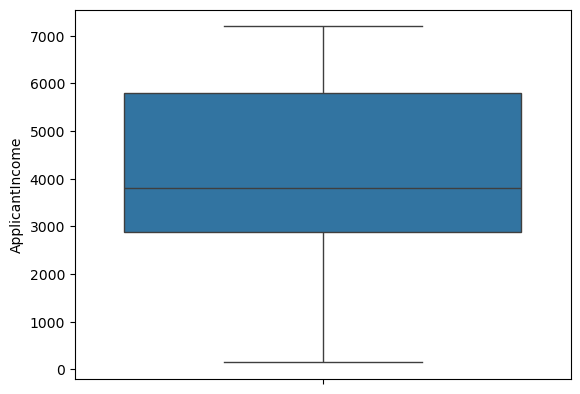

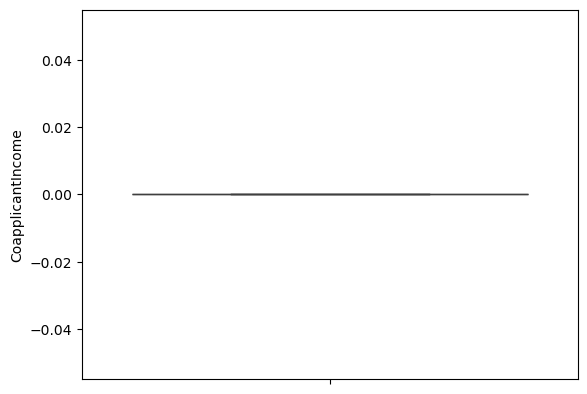

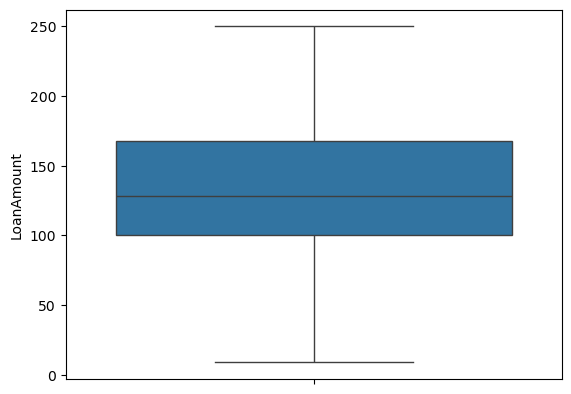

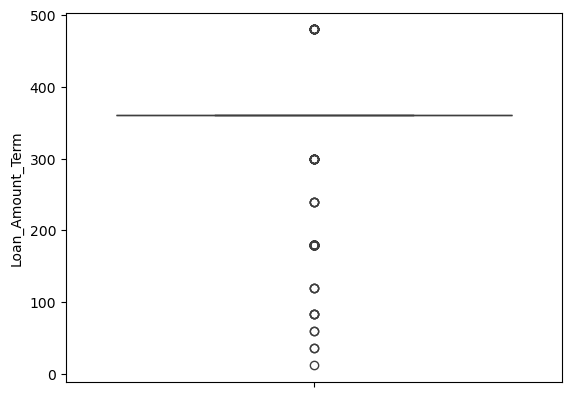

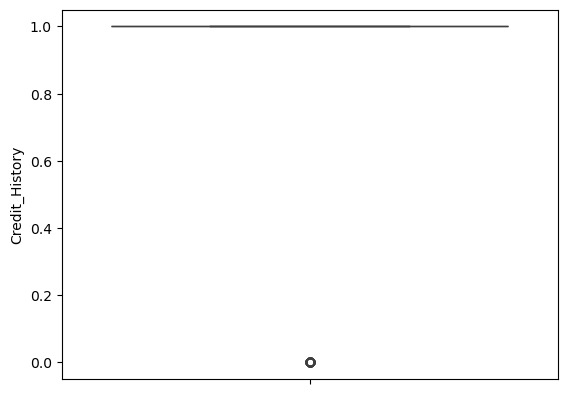

In [18]:
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

In [19]:
df.describe(include="number")

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.0,592.000000,600.00000,564.000000
mean,4260.432003,0.0,136.778716,342.00000,0.842199
std,1797.384795,0.0,54.793259,65.12041,0.364878
min,150.000000,0.0,9.000000,12.00000,0.000000
25%,2877.500000,0.0,100.000000,360.00000,1.000000
50%,3812.500000,0.0,128.000000,360.00000,1.000000
75%,5795.000000,0.0,168.000000,360.00000,1.000000
max,7193.750000,0.0,250.000000,480.00000,1.000000


**Univariate Analysis**

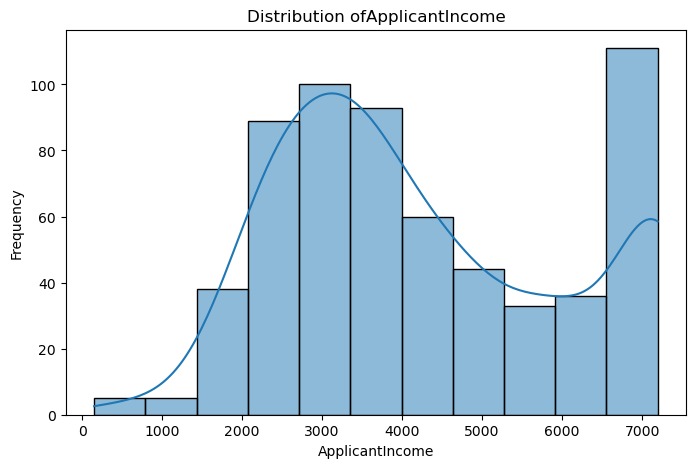

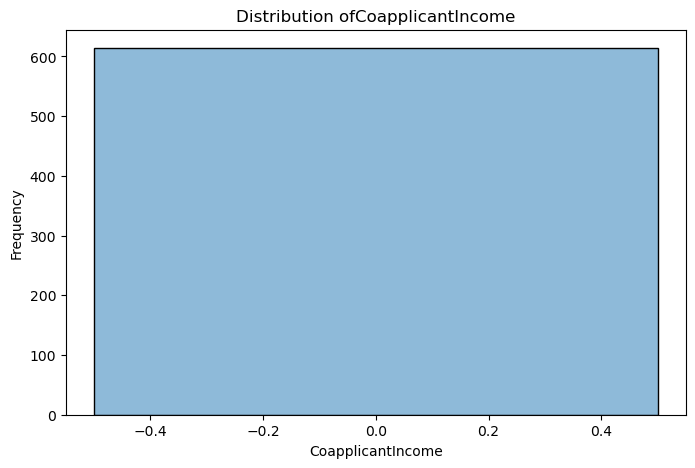

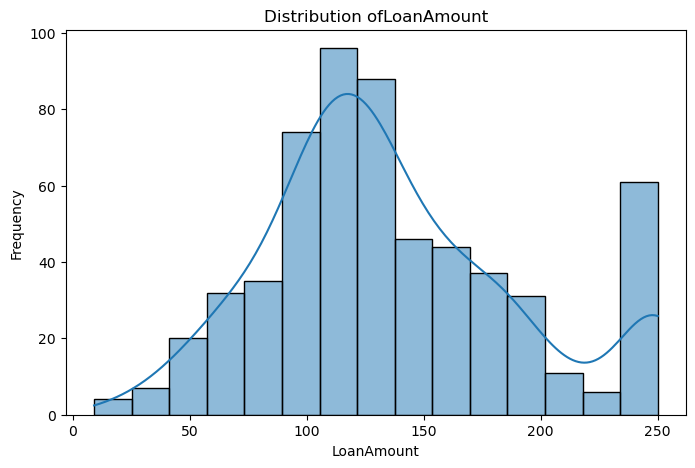

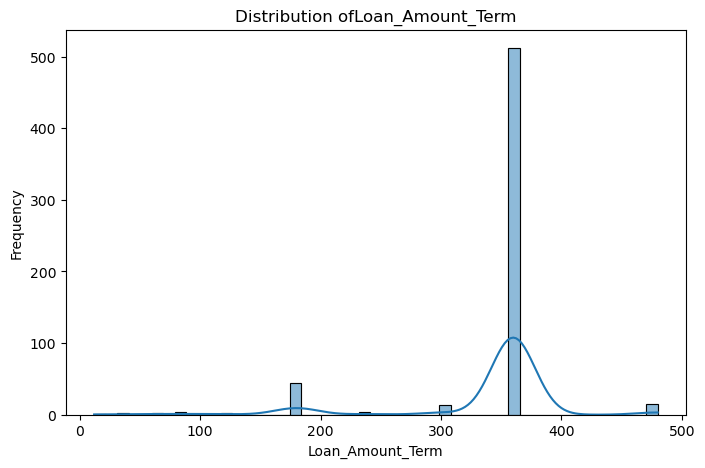

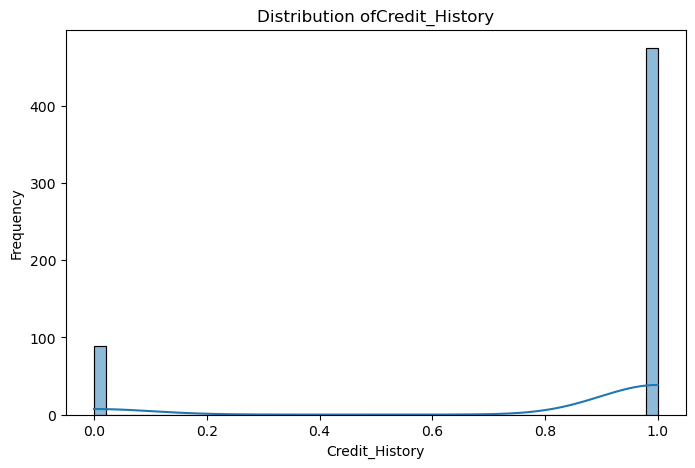

In [20]:
for i in numerical_cols:
    plt.figure(figsize=(8,5))
    sns.histplot(df[i],kde=True)
    plt.title(f"Distribution of{i}")
    plt.xlabel(i)
    plt.ylabel("Frequency")

    plt.show()

In [21]:
#Interpretation: ApplicantIncome is slightly positively skewed distributed
#CoapplicantIncome is positively skewed distributed
#LoanAmount distribution is symmetric

In [22]:
#Removing unnecessary columns

In [23]:
df.drop(columns=["Loan_ID"],inplace=True)

In [24]:
categorical_cols = df.select_dtypes(include = 'object').columns
categorical_cols

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Property_Area', 'Loan_Status'],
      dtype='str')

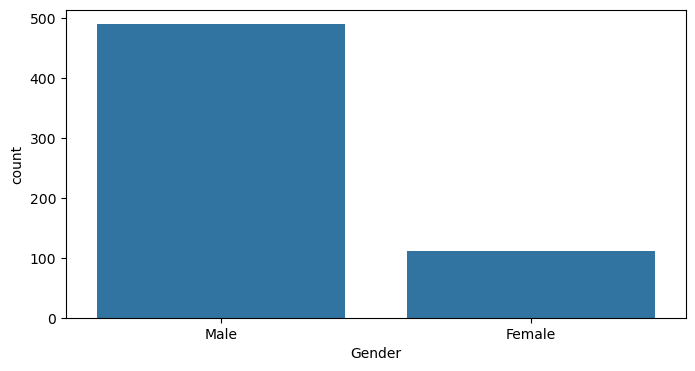

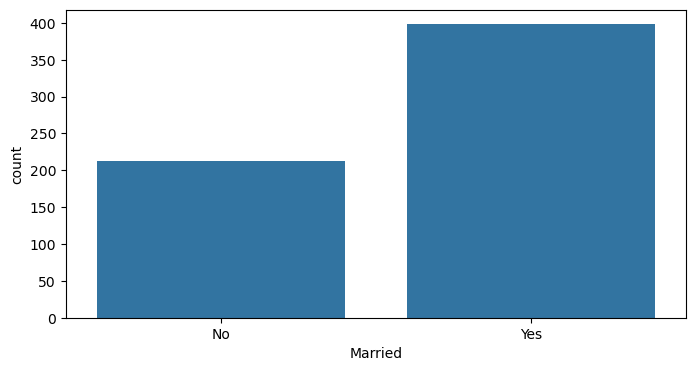

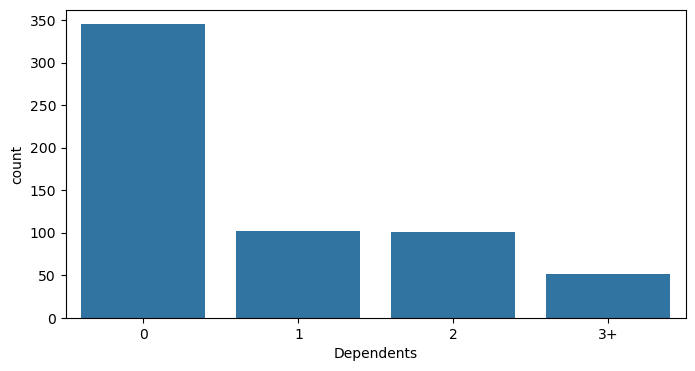

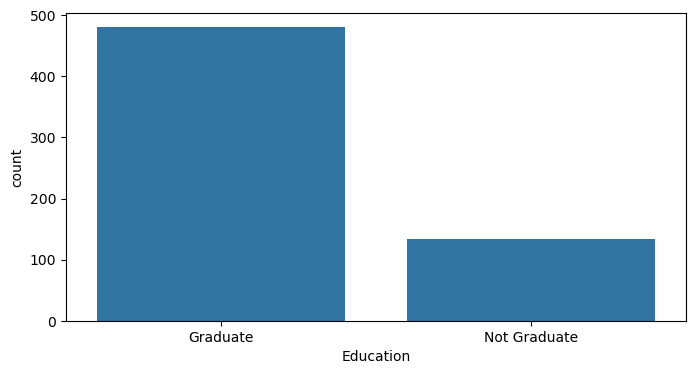

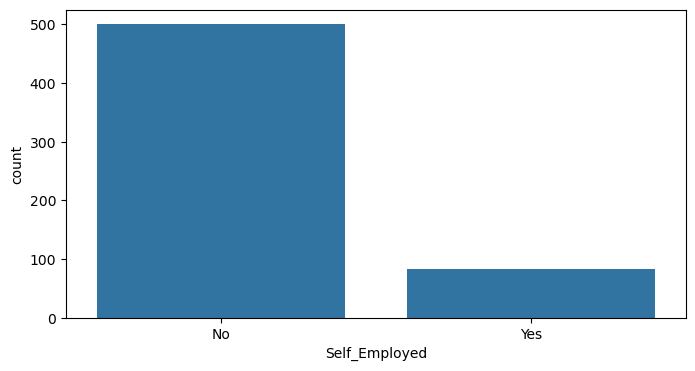

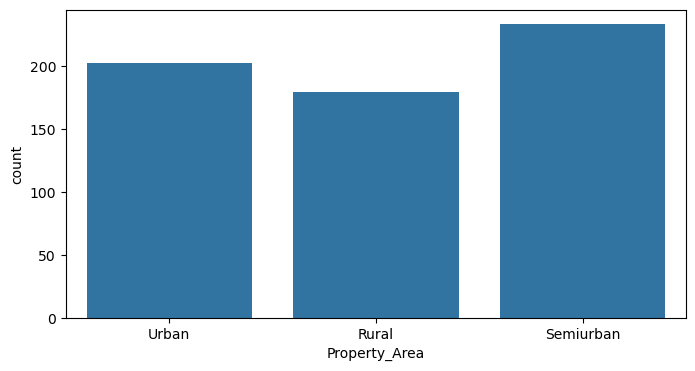

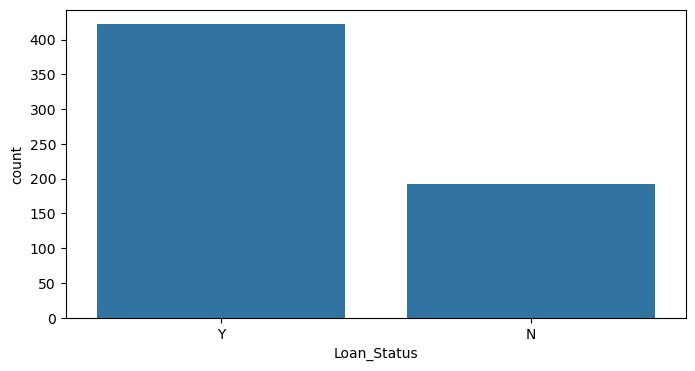

In [25]:
for i in categorical_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df,x=i)
    plt.show()

In [26]:
#Interpretation: Male candidates apply to loan more than Female candidates
#Married people are more as compared to unmarried people in our data
#Married men's applying more to loan
#Graduate count is more in our data
#Self employeed count is less in our data means self employeed people are less likely
#applying for loans

# Multivariate analysis

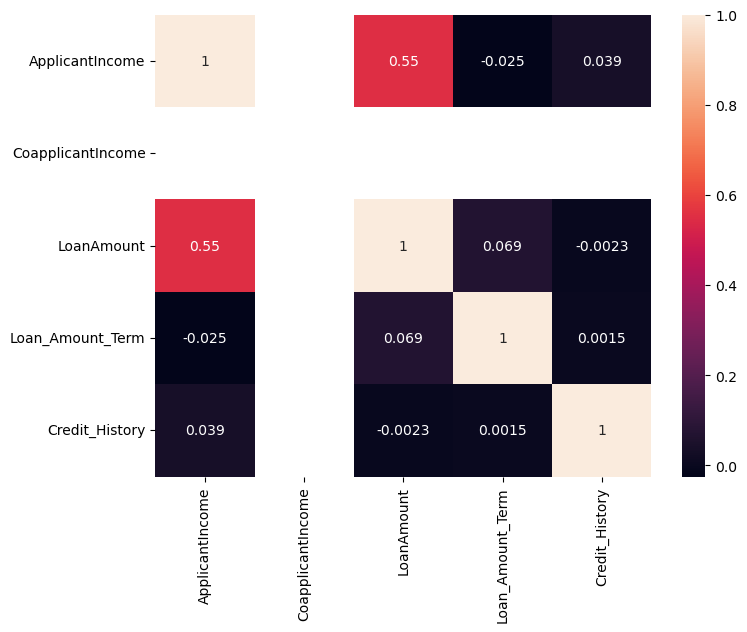

In [27]:
#Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(
    df[numerical_cols].corr(),
    annot=True
)
plt.show()

In [28]:
#There is  considered correlation between income & loan amount

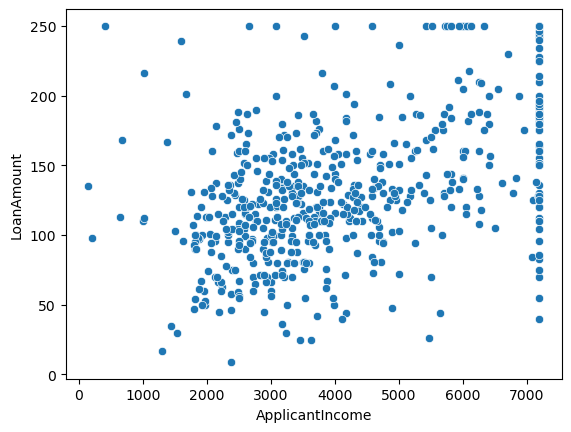

In [29]:
sns.scatterplot(data=df,x="ApplicantIncome",y="LoanAmount")
plt.show()

**Group by analysis**

In [30]:
#1)Average Applicant Income By Gender
print(df.groupby('Gender')["ApplicantIncome"].mean())
#2)Average loan amount by education
print(df.groupby('Education')["LoanAmount"].mean())
#3)Total applicant Income by property Area
print(df.groupby('Property_Area')["ApplicantIncome"].sum())
#4)Average loan amount By property Area
print(df.groupby('Property_Area')["LoanAmount"].mean())

Gender
Female    3933.569196
Male      4328.197853
Name: ApplicantIncome, dtype: float64
Education
Graduate        141.858065
Not Graduate    118.181102
Name: LoanAmount, dtype: float64
Property_Area
Rural        788515.25
Semiurban    987320.00
Urban        840070.00
Name: ApplicantIncome, dtype: float64
Property_Area
Rural        142.208092
Semiurban    137.280702
Urban        131.261780
Name: LoanAmount, dtype: float64


In [31]:
#Interpretation: from this we conclude that male candidates earning more than female candidates
#but here male count is also more than female count
#more than is taken by graduate than non graduates
#people staying in semiurban area earning more but
#people staying in rural area taking more loans and earning less

In [32]:
#Loan approval count by Education  
print(df.groupby("Education")["Loan_Status"].value_counts())
#Average income by loan status
print(df.groupby("Loan_Status")["ApplicantIncome"].mean())

Education     Loan_Status
Graduate      Y              340
              N              140
Not Graduate  Y               82
              N               52
Name: count, dtype: int64
Loan_Status
N    4256.563802
Y    4262.191943
Name: ApplicantIncome, dtype: float64


Interpretation=> Graduates:340 loan were approved & 140 were rejected.
Not graduates: 92 loans were approved & 52 were rejected.
So,graduates have a higher loan approval count than non=graduates.
However,number of applicants in each group is different, so counts alone don't tell us the approval rate.
For the second analysis:
Average income of applicants whose loan was rejected(N)=4618.74
Average income of applicants whose loan was approved(Y)=4616.37.
The difference is only about 2.36,which is extremely small.
Overall conclusion:
Education appears to have some association with loan approval,with graduate having more loan approval.
However,applicant income does not appear to have a meaningful difference between approved & rejected loans in this dataset.
Therefore,income alone does not strongly infuence loan approval.

In [35]:
df.to_csv(r"C:\Users\Admin\Downloads\LoanApproval.csv",index=False)